# CNN in Deep Learning — CIFAR-10 Complete Hands-On Project
## Beginner → Intermediate → Practical CNN

**Dataset:** CIFAR-10  
**Framework:** TensorFlow / Keras  
**Environment:** Google Colab or Jupyter Notebook

This notebook is designed to build CNN understanding conceptually while giving you hands-on implementation.

### Topics covered
- Image tensors and RGB channels
- Convolution, filters/kernels and feature maps
- ReLU and other activations
- Padding and stride
- Pooling
- CNN output-shape calculations
- CNN parameter calculations
- Flatten vs GlobalAveragePooling
- Batch Normalization
- Dropout
- Data augmentation
- Softmax and cross-entropy
- Adam, learning rate, epochs and batch size
- Forward pass and backpropagation
- Early stopping and learning-rate scheduling
- Confusion matrix and classification report
- Error analysis
- Feature-map visualization
- Saving/loading a model
- Single-image prediction
- CNN architecture experiments

> **Practice rule:** Before running a major cell, predict the output shape and explain what the layer should learn.

## 1. Dataset — CIFAR-10

CIFAR-10 contains **60,000 color images** across 10 classes. Each image is **32 × 32 × 3**.

Classes:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`

Standard split:
- 50,000 training images
- 10,000 test images

### Dataset resources

- Official dataset: https://www.cs.toronto.edu/~kriz/cifar.html
- TensorFlow/Keras: https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10
- Kaggle: https://www.kaggle.com/c/cifar-10
- Kaggle datasets search: https://www.kaggle.com/datasets?search=cifar-10

The notebook downloads CIFAR-10 automatically using Keras, so manual download is normally unnecessary.

## 2. Environment Setup

### Local Jupyter

```bash
pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow
```

### Google Colab

Run the installation cell below only if required.

In [ ]:
# Optional installation
# %pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.2.6


## 3. Reproducibility

Reproducibility is useful when comparing CNN experiments.

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seed:", SEED)

Seed: 42


## 4. Load CIFAR-10

In [3]:
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train:", X_train_raw.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test.shape)
print("Classes:", len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2144s 13us/step
X_train: (50000, 32, 32, 3)
y_train: (50000, 1)
X_test : (10000, 32, 32, 3)
y_test : (10000, 1)
Classes: 10


### Shape interpretation

`X_train = (50000, 32, 32, 3)`

- 50,000 = number of images
- 32 = height
- 32 = width
- 3 = RGB channels

A batch of 64 images has shape:

`(64, 32, 32, 3)`

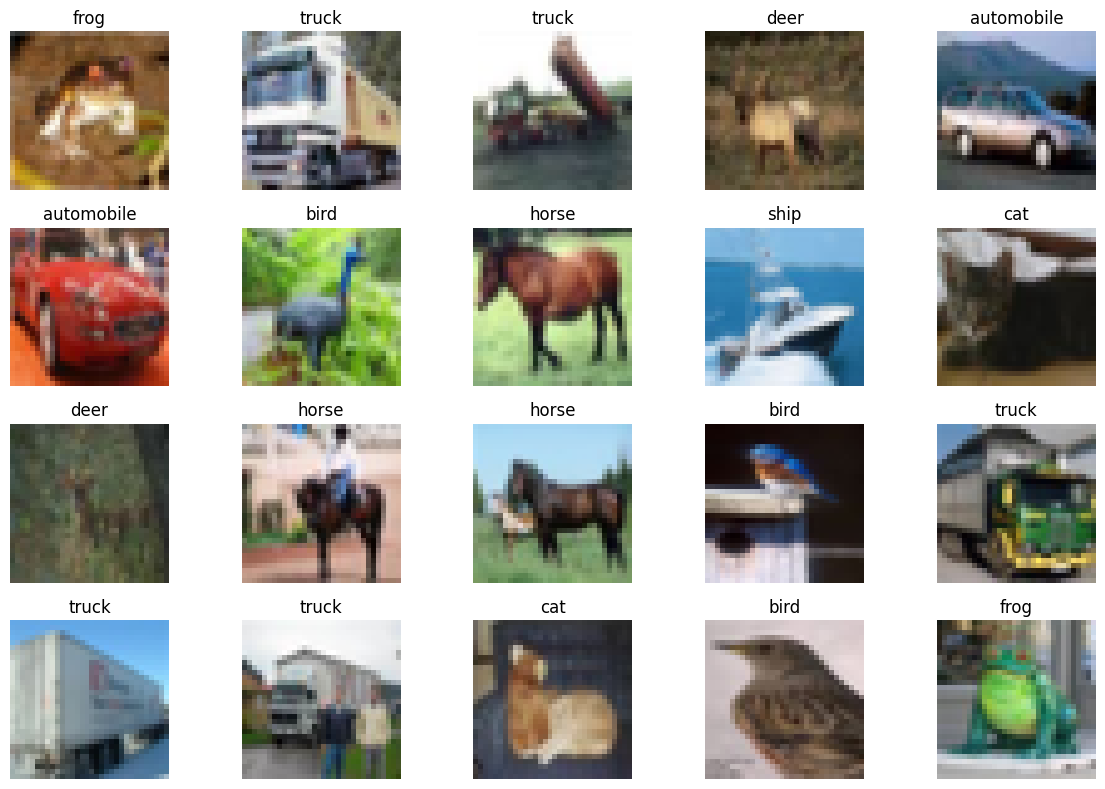

In [4]:
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_train_raw[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

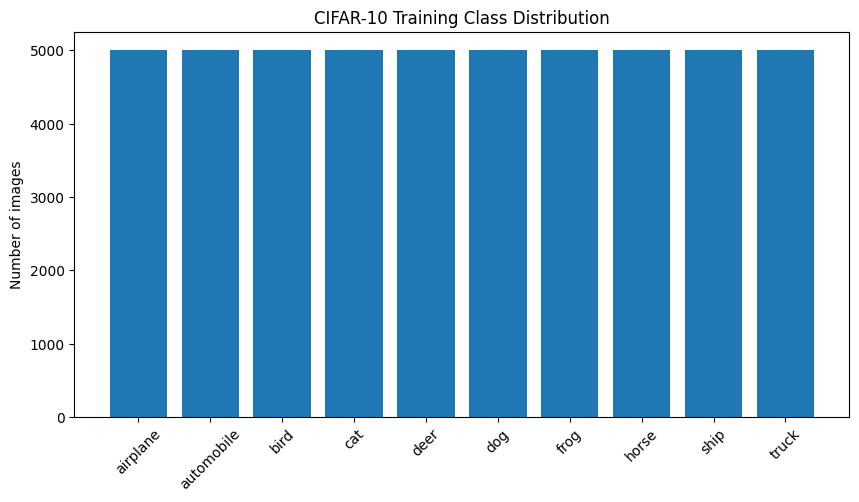

{'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


In [5]:
counts = np.bincount(y_train.flatten(), minlength=10)

plt.figure(figsize=(10, 5))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("CIFAR-10 Training Class Distribution")
plt.show()

print(dict(zip(class_names, counts)))

## 5. Image Tensor and Pixel Values

Raw CIFAR-10 pixel values are approximately **0–255**.

CNN inputs are commonly normalized to **0–1**:

`X_normalized = X / 255.0`

Raw minimum: 0
Raw maximum: 255


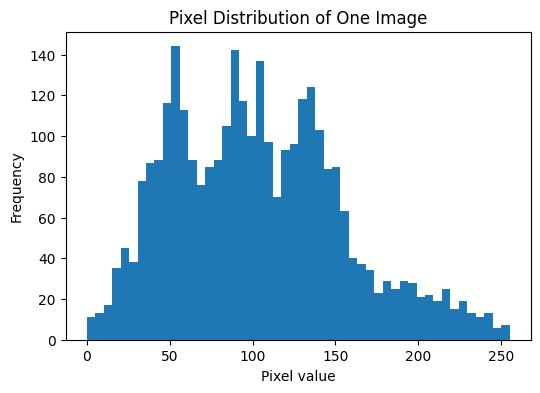

In [6]:
print("Raw minimum:", X_train_raw.min())
print("Raw maximum:", X_train_raw.max())

plt.figure(figsize=(6, 4))
plt.hist(X_train_raw[0].ravel(), bins=50)
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.title("Pixel Distribution of One Image")
plt.show()

In [7]:
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

print("Normalized range:", X_train.min(), "to", X_train.max())

Normalized range: 0.0 to 1.0


## 6. Labels

CIFAR-10 labels are integer class IDs from 0 to 9.

For `categorical_crossentropy`, we can use one-hot encoded labels.

In [8]:
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

print("Integer label:", y_train[0, 0])
print("One-hot label:", y_train_cat[0])

Integer label: 6
One-hot label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


# 7. CNN Mental Model

```text
IMAGE
  ↓
CONVOLUTION
  ↓
FILTERS / KERNELS
  ↓
FEATURE MAPS
  ↓
RELU
  ↓
POOLING
  ↓
DEEPER FEATURES
  ↓
FLATTEN / GLOBAL AVERAGE POOLING
  ↓
DENSE
  ↓
SOFTMAX
  ↓
CLASS PROBABILITIES
  ↓
LOSS
  ↓
BACKPROPAGATION
  ↓
OPTIMIZER
  ↓
UPDATED WEIGHTS
```

Early convolution layers often learn local patterns such as edges and textures. Deeper layers combine features into more complex representations.

## 8. Convolution Parameters

Important `Conv2D` parameters:

| Parameter | Meaning |
|---|---|
| `filters` | Number of learned feature detectors |
| `kernel_size` | Spatial size of each kernel |
| `strides` | Step size of kernel movement |
| `padding` | Border handling |
| `dilation_rate` | Kernel spacing |
| `activation` | Non-linearity applied after convolution |

For standard convolution:

**Parameters = `(kernel_h × kernel_w × input_channels + 1) × filters`**

For dilation 1:

**Output = floor((N + 2P − K) / S + 1)**

For `padding="same"` with stride 1, spatial dimensions are preserved.

In [9]:
# Parameter calculation example
input_channels = 3
kernel_h = 3
kernel_w = 3
filters = 64

params = (kernel_h * kernel_w * input_channels + 1) * filters
print("Conv2D parameters:", params)

print("32x32 + valid 3x3 + stride 1 -> 30x30")
print("32x32 + same  3x3 + stride 1 -> 32x32")
print("32x32 + 2x2 max pooling        -> 16x16")

Conv2D parameters: 1792
32x32 + valid 3x3 + stride 1 -> 30x30
32x32 + same  3x3 + stride 1 -> 32x32
32x32 + 2x2 max pooling        -> 16x16


## 9. Filter / Feature Map Concept

For an RGB image:

```text
Input: 32 × 32 × 3
Kernel: 3 × 3 × 3
Number of filters: 32

Output with same padding + stride 1:
32 × 32 × 32
```

The kernel depth must match the input channel depth.

Filters learn patterns such as:
- edges
- corners
- color transitions
- textures
- simple shapes

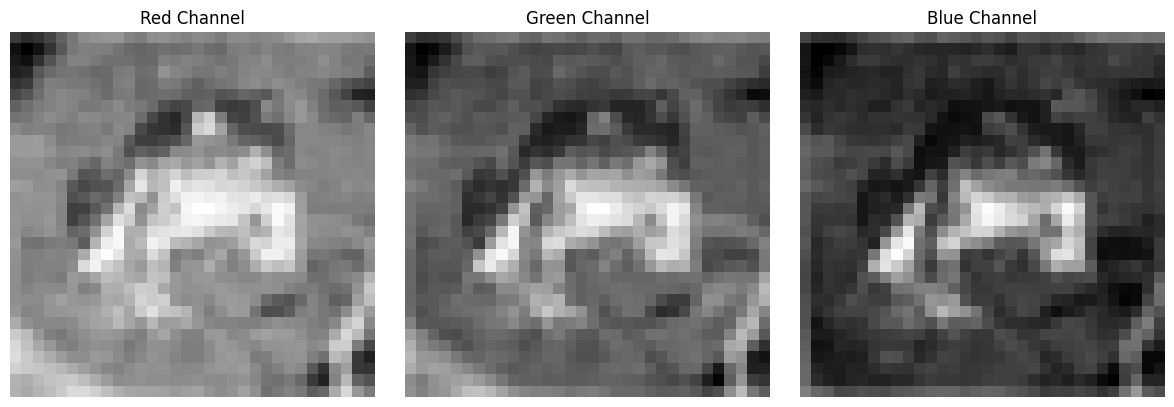

In [10]:
image = X_train[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, channel in enumerate(["Red", "Green", "Blue"]):
    axes[i].imshow(image[:, :, i], cmap="gray")
    axes[i].set_title(channel + " Channel")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# 10. Activation Functions

### ReLU

`ReLU(x) = max(0, x)`

It introduces non-linearity and is widely used in CNN hidden layers.

### Other useful activations

- Sigmoid — binary probabilities / gates
- Tanh — centered bounded activation
- GELU — common in modern architectures
- Softmax — multi-class probability distribution

For this CIFAR-10 classifier, ReLU is used in hidden layers and Softmax in the final layer.

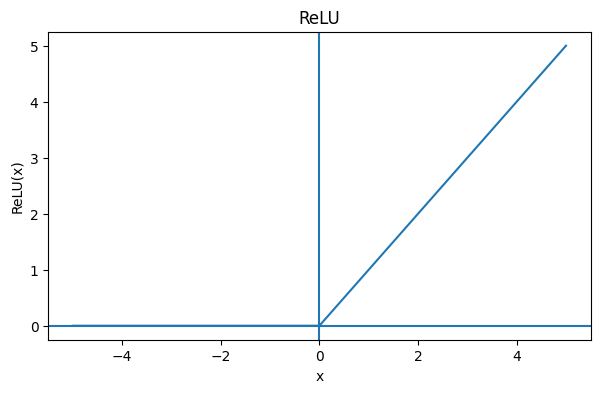

In [11]:
def relu(x):
    return np.maximum(0, x)

x = np.linspace(-5, 5, 400)

plt.figure(figsize=(7, 4))
plt.plot(x, relu(x))
plt.axhline(0)
plt.axvline(0)
plt.title("ReLU")
plt.xlabel("x")
plt.ylabel("ReLU(x)")
plt.show()

# 11. Padding and Stride Hands-On

### Padding
- `valid`: no padding
- `same`: preserves spatial dimensions when stride = 1

### Stride
Stride controls how far the filter moves.

Example:
- input = 32
- kernel = 3
- stride = 1
- valid → 30
- same → 32

Increasing stride reduces spatial resolution.

In [12]:
shape_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, padding="valid", activation="relu"),
])

shape_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,392 (75.75 KB)

 Trainable params: 19,392 (75.75 KB)

 Non-trainable params: 0 (0.00 B)

# 12. Pooling

Pooling reduces spatial dimensions.

### MaxPooling
Takes the maximum value in each pooling window.

### AveragePooling
Takes the average.

Example:

`32 × 32 → 16 × 16` using `2 × 2` pooling with stride 2.

Pooling can reduce computation and provide some spatial robustness.

In [13]:
pool_demo = np.array([
    [1, 3, 2, 0],
    [4, 6, 5, 1],
    [2, 8, 7, 3],
    [0, 2, 1, 9]
])

print("Input:")
print(pool_demo)

print("\n2x2 max pooling result:")
print(tf.nn.max_pool2d(pool_demo[None, :, :, None], ksize=2, strides=2, padding="VALID").numpy()[0, :, :, 0])

Input:
[[1 3 2 0]
 [4 6 5 1]
 [2 8 7 3]
 [0 2 1 9]]

2x2 max pooling result:
[[6. 5.]
 [8. 9.]]


# 13. Baseline CNN

Architecture:

```text
32×32×3
 ↓
Conv2D 32, 3×3, ReLU
 ↓
MaxPool 2×2
 ↓
Conv2D 64, 3×3, ReLU
 ↓
MaxPool 2×2
 ↓
Conv2D 128, 3×3, ReLU
 ↓
Flatten
 ↓
Dense 128, ReLU
 ↓
Dropout 0.30
 ↓
Dense 10, Softmax
```

In [14]:
baseline = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
], name="baseline_cnn")

baseline.summary()
print("Total parameters:", baseline.count_params())

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 1143242


## 14. Compile — Loss, Optimizer and Metrics

For 10-class classification:

- Output activation: Softmax
- Loss: categorical cross-entropy
- Optimizer: Adam
- Metric: accuracy

### Important optimizer parameters

`learning_rate` controls the step size of weight updates.

A very large learning rate can make training unstable. A very small learning rate can make training slow.

In [15]:
baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

## 15. Train the Baseline CNN

Key training parameters:

- `batch_size`: number of samples per gradient update
- `epochs`: number of passes through the training data
- `validation_split`: fraction used for validation
- `callbacks`: training controls such as early stopping

In [16]:
start = time.time()

history = baseline.fit(
    X_train,
    y_train_cat,
    validation_split=0.10,
    epochs=20,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

baseline_training_time = time.time() - start
print(f"Training time: {baseline_training_time:.2f} seconds")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.4443 - loss: 1.5337 - val_accuracy: 0.5844 - val_loss: 1.1619 - learning_rate: 0.0010
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.5934 - loss: 1.1423 - val_accuracy: 0.6426 - val_loss: 1.0249 - learning_rate: 0.0010
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.6633 - loss: 0.9584 - val_accuracy: 0.7000 - val_loss: 0.8720 - learning_rate: 0.0010
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.7067 - loss: 0.8359 - val_accuracy: 0.7050 - val_loss: 0.8366 - learning_rate: 0.0010
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.7392 - loss: 0.7372 - val_accuracy: 0.7198 - val_loss: 0.7950 - learning_rate: 0.0010
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.7685 - loss: 0.6550 - val_accuracy: 0.7206 - val_loss: 0.8197 - learning_rate: 0.0010
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.7922 - l

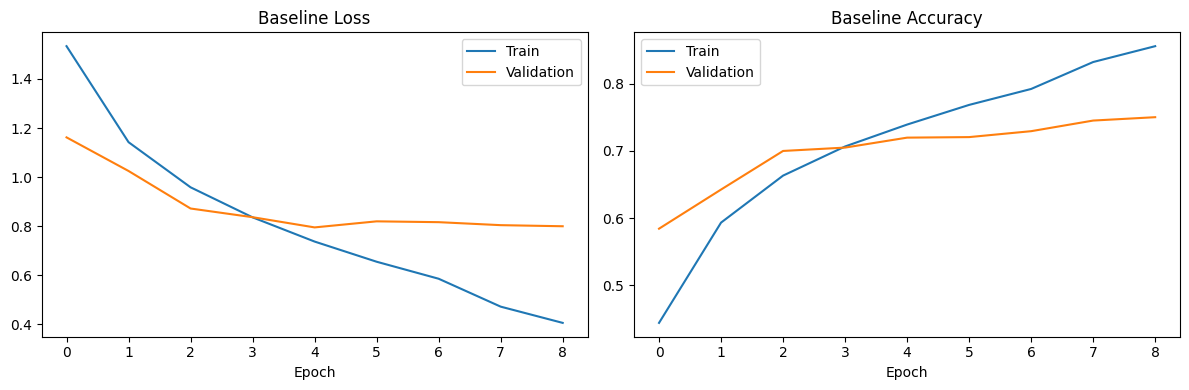

In [17]:
h = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(h["loss"], label="Train")
axes[0].plot(h["val_loss"], label="Validation")
axes[0].set_title("Baseline Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(h["accuracy"], label="Train")
axes[1].plot(h["val_accuracy"], label="Validation")
axes[1].set_title("Baseline Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [18]:
baseline_loss, baseline_acc = baseline.evaluate(X_test, y_test_cat, verbose=0)
print(f"Baseline test loss: {baseline_loss:.4f}")
print(f"Baseline test accuracy: {baseline_acc:.4f}")

Baseline test loss: 0.8387
Baseline test accuracy: 0.7057


# 16. Predictions

Softmax returns 10 probabilities. `argmax` selects the class with the highest probability.

In [19]:
probs = baseline.predict(X_test[:10], verbose=0)
pred = np.argmax(probs, axis=1)
actual = y_test[:10].flatten()

for i in range(10):
    print(
        f"Image {i}: "
        f"actual={class_names[actual[i]]}, "
        f"predicted={class_names[pred[i]]}, "
        f"confidence={probs[i].max():.3f}"
    )

Image 0: actual=cat, predicted=dog, confidence=0.518
Image 1: actual=ship, predicted=ship, confidence=0.986
Image 2: actual=ship, predicted=ship, confidence=0.460
Image 3: actual=airplane, predicted=airplane, confidence=0.619
Image 4: actual=frog, predicted=frog, confidence=0.970
Image 5: actual=frog, predicted=frog, confidence=0.935
Image 6: actual=automobile, predicted=automobile, confidence=0.977
Image 7: actual=frog, predicted=frog, confidence=0.573
Image 8: actual=cat, predicted=cat, confidence=0.536
Image 9: actual=automobile, predicted=automobile, confidence=0.894


# 17. Confusion Matrix and Classification Report

Accuracy gives one overall number. A confusion matrix shows which classes are confused with each other.

We will inspect:
- Precision
- Recall
- F1-score
- Confusion matrix

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
              precision    recall  f1-score   support

    airplane     0.8069    0.7060    0.7531      1000
  automobile     0.8674    0.7460    0.8022      1000
        bird     0.6213    0.5480    0.5824      1000
         cat     0.5488    0.4670    0.5046      1000
        deer     0.5757    0.7340    0.6453      1000
         dog     0.6016    0.6570    0.6281      1000
        frog     0.7016    0.8440    0.7662      1000
       horse     0.7996    0.7380    0.7676      1000
        ship     0.8340    0.8040    0.8187      1000
       truck     0.7563    0.8130    0.7836      1000

    accuracy                         0.7057     10000
   macro avg     0.7113    0.7057    0.7052     10000
weighted avg     0.7113    0.7057    0.7052     10000



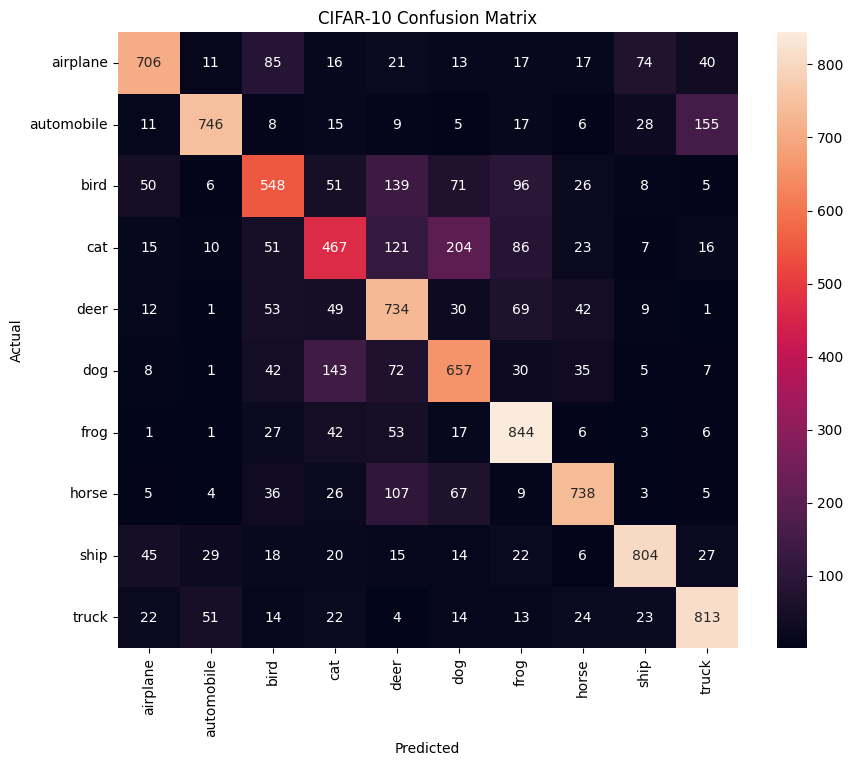

In [20]:
all_probs = baseline.predict(X_test, batch_size=256, verbose=1)
all_pred = np.argmax(all_probs, axis=1)
all_actual = y_test.flatten()

print(classification_report(
    all_actual,
    all_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(all_actual, all_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

# 18. Data Augmentation

Common image augmentation techniques:

- Random horizontal flip
- Translation
- Rotation
- Zoom

Augmentation should be applied to training data. The final test set should remain representative of the real evaluation distribution.

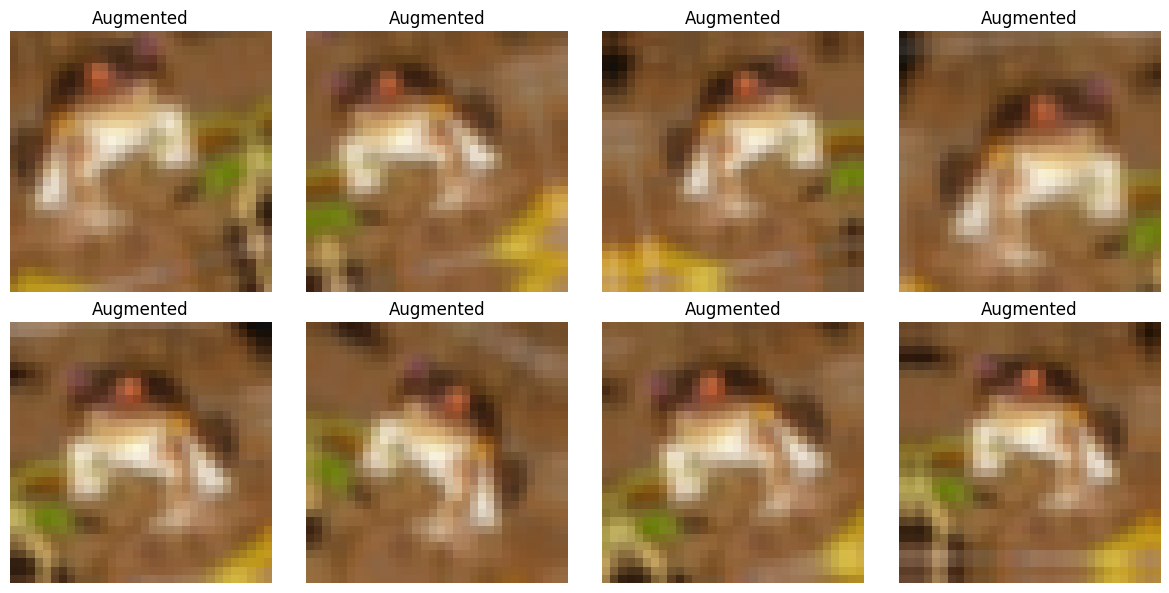

In [21]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
], name="data_augmentation")

sample = X_train[0:1]

plt.figure(figsize=(12, 6))
for i in range(8):
    augmented = augmentation(sample, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(augmented[0])
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 19. Batch Normalization

Batch Normalization normalizes intermediate activations during training and can make optimization more stable.

Typical pattern:

```text
Conv2D
 ↓
BatchNormalization
 ↓
ReLU
```

# 20. Improved CNN — BatchNorm + Augmentation + GAP

Architecture:

```text
Input
 ↓
Augmentation
 ↓
Conv → BatchNorm → ReLU
 ↓
Conv → BatchNorm → ReLU
 ↓
MaxPool → Dropout
 ↓
Conv → BatchNorm → ReLU
 ↓
Conv → BatchNorm → ReLU
 ↓
MaxPool → Dropout
 ↓
Conv → BatchNorm → ReLU
 ↓
GlobalAveragePooling
 ↓
Dense → Dropout
 ↓
Softmax
```

`GlobalAveragePooling2D` summarizes each feature map and usually uses fewer parameters than Flatten followed by a large Dense layer.

In [25]:
improved = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    augmentation,

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D(2),
    layers.Dropout(0.20),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(10, activation="softmax")
], name="improved_cnn")

improved.summary()
print("Total parameters:", improved.count_params())

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,51

 Total params: 158,186 (617.91 KB)

 Trainable params: 157,546 (615.41 KB)

 Non-trainable params: 640 (2.50 KB)

Total parameters: 158186


In [26]:
improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

improved_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

start = time.time()

improved_history = improved.fit(
    X_train,
    y_train_cat,
    validation_split=0.10,
    epochs=30,
    batch_size=64,
    callbacks=improved_callbacks,
    verbose=1
)

improved_training_time = time.time() - start
print(f"Training time: {improved_training_time:.2f} seconds")

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 93ms/step - accuracy: 0.3882 - loss: 1.6547 - val_accuracy: 0.4430 - val_loss: 1.5872 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 117ms/step - accuracy: 0.5004 - loss: 1.3763 - val_accuracy: 0.4722 - val_loss: 1.4563 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 89s 126ms/step - accuracy: 0.5464 - loss: 1.2629 - val_accuracy: 0.4578 - val_loss: 1.7870 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 94s 134ms/step - accuracy: 0.5768 - loss: 1.1894 - val_accuracy: 0.5188 - val_loss: 1.5355 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 93s 132ms/step - accuracy: 0.6127 - loss: 1.0927 - val_accuracy: 0.5758 - val_loss: 1.2529 - learning_rate: 5.0000e-04
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 88s 125ms/step - accuracy: 0.6247 - loss: 1.0628 - val_accuracy: 0.6024 - val_loss: 1.1605 - learning_rate: 5.0000e-04
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 86s 122ms/step - accura

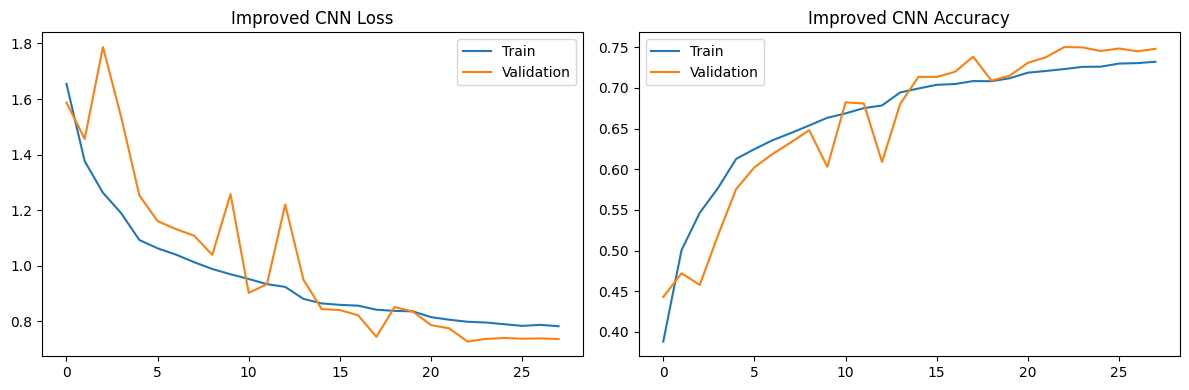

In [27]:
ih = pd.DataFrame(improved_history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ih["loss"], label="Train")
axes[0].plot(ih["val_loss"], label="Validation")
axes[0].set_title("Improved CNN Loss")
axes[0].legend()

axes[1].plot(ih["accuracy"], label="Train")
axes[1].plot(ih["val_accuracy"], label="Validation")
axes[1].set_title("Improved CNN Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [28]:
improved_loss, improved_acc = improved.evaluate(X_test, y_test_cat, verbose=0)

comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Test Accuracy": [baseline_acc, improved_acc],
    "Test Loss": [baseline_loss, improved_loss],
    "Parameters": [baseline.count_params(), improved.count_params()],
    "Training Time (sec)": [baseline_training_time, improved_training_time]
})

comparison

,Model,Test Accuracy,Test Loss,Parameters,Training Time (sec)
0,Baseline CNN,0.7057,0.838722,1143242,185.155205
1,Improved CNN,0.7425,0.759241,158186,2223.417519


# 21. Feature Maps

Feature maps are the outputs of convolution layers.

Do not assume every feature map corresponds to a human-interpretable object. Early maps may respond to simple local patterns; deeper maps can represent more complex combinations.

In [33]:
conv_layers = [layer for layer in improved.layers if isinstance(layer, layers.Conv2D)]

print("Convolution layers:")
for i, layer in enumerate(conv_layers):
    print(i, layer.name, layer.output.shape)

activation_model = keras.Model(
    inputs=improved.input,
    outputs=[layer.output for layer in conv_layers]
)

activations = activation_model.predict(X_test[:1], verbose=0)

for i, activation in enumerate(activations):
    print(f"Conv output {i}: {activation.shape}")

Convolution layers:
0 conv2d_20 (None, 32, 32, 32)
1 conv2d_21 (None, 32, 32, 32)
2 conv2d_22 (None, 16, 16, 64)
3 conv2d_23 (None, 16, 16, 64)
4 conv2d_24 (None, 8, 8, 128)


AttributeError: The layer improved_cnn has never been called and thus has no defined input.

In [39]:
# import tensorflow as tf
# from tensorflow import keras

# # Get convolutional layers
# conv_layers = [
#     layer for layer in improved.layers
#     if isinstance(layer, keras.layers.Conv2D)
# ]

# # Display convolutional layers
# for i, layer in enumerate(conv_layers):
#     print(i, layer.name, layer.output.shape if hasattr(layer, "output") else "No symbolic output")


# # Create symbolic input
# input_shape = X_test.shape[1:]

# inputs = keras.Input(shape=input_shape)

# # Call the model with symbolic input
# x = inputs

# for layer in improved.layers:
#     x = layer(x)

# # Create activation model
# activation_model = keras.Model(
#     inputs=inputs,
#     outputs=[layer(x) for layer in []]
# )

In [ ]:
first_activation = activations[0][0]

plt.figure(figsize=(12, 8))
for i in range(min(16, first_activation.shape[-1])):
    plt.subplot(4, 4, i + 1)
    plt.imshow(first_activation[:, :, i])
    plt.title(f"Map {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 22. Error Analysis

A practical CNN project should investigate errors, not only accuracy.

Questions:
- Which classes are confused?
- Are objects small?
- Are images ambiguous?
- Is image quality poor?
- Are two classes visually similar?
- Is the model overfitting?
- Is the train/validation distribution reasonable?
- Is there a data or label problem?

Incorrect predictions: 2943
First 20 wrong indices: [ 0 15 21 22 24 25 33 35 37 42 47 52 57 58 59 61 63 69 76 85]


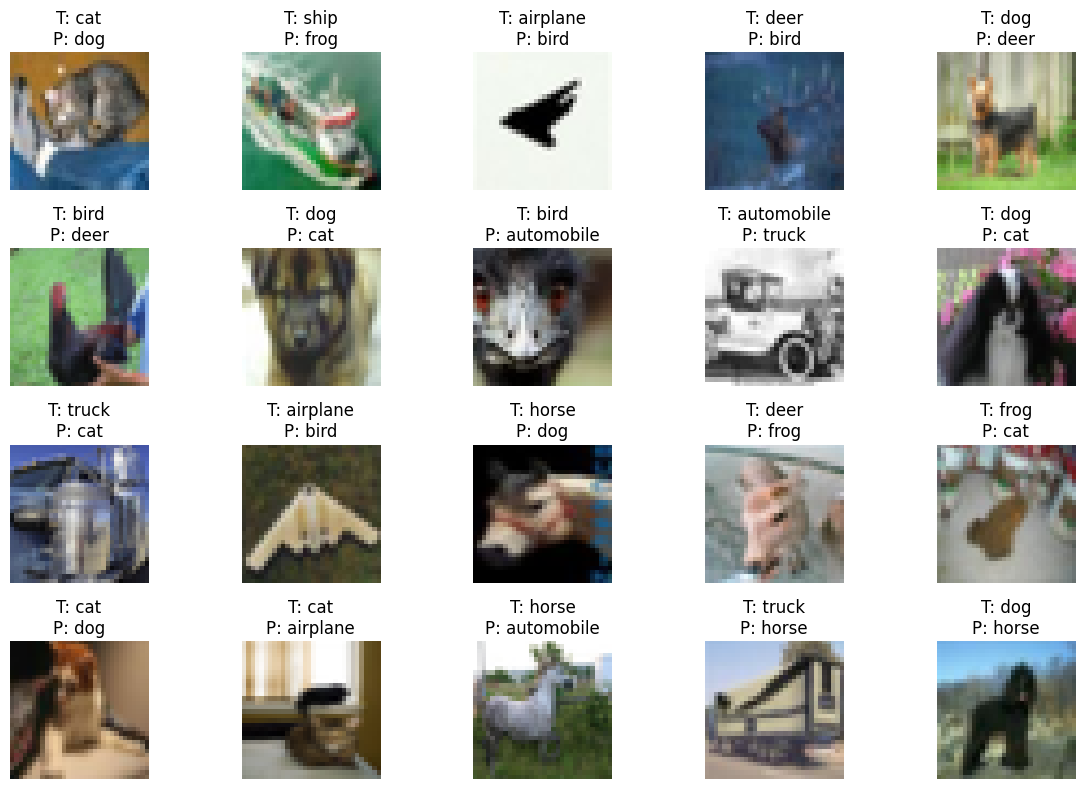

In [35]:
wrong_indices = np.where(all_pred != all_actual)[0]

print("Incorrect predictions:", len(wrong_indices))
print("First 20 wrong indices:", wrong_indices[:20])

plt.figure(figsize=(12, 8))

for j, idx in enumerate(wrong_indices[:20]):
    plt.subplot(4, 5, j + 1)
    plt.imshow(X_test[idx])
    true_name = class_names[all_actual[idx]]
    pred_name = class_names[all_pred[idx]]
    plt.title(f"T: {true_name}\nP: {pred_name}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 23. Save and Load the Model

Typical lifecycle:

```text
Train
 ↓
Evaluate
 ↓
Save
 ↓
Deploy
 ↓
Load
 ↓
Predict
```

Keras supports the `.keras` model format.

In [36]:
model_path = "cifar10_improved_cnn.keras"

improved.save(model_path)

loaded_model = keras.models.load_model(model_path)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    X_test[:1000],
    y_test_cat[:1000],
    verbose=0
)

print("Saved:", model_path)
print("Loaded model accuracy on first 1000 test images:", loaded_accuracy)

Saved: cifar10_improved_cnn.keras
Loaded model accuracy on first 1000 test images: 0.7379999756813049


# 24. Single-Image Prediction

Production-style preprocessing:

```text
Image
 ↓
Resize
 ↓
RGB conversion
 ↓
Normalize
 ↓
Add batch dimension
 ↓
CNN
 ↓
Softmax
 ↓
Class + confidence
```

In [37]:
def predict_image(model, image, class_names):
    image_batch = np.expand_dims(image, axis=0)
    probabilities = model.predict(image_batch, verbose=0)[0]
    index = int(np.argmax(probabilities))

    return {
        "class": class_names[index],
        "confidence": float(probabilities[index]),
        "probabilities": probabilities
    }

result = predict_image(improved, X_test[0], class_names)

print("Prediction:", result["class"])
print("Confidence:", result["confidence"])

Prediction: cat
Confidence: 0.8153443336486816


# 25. CNN Parameters — Experiment Lab

Change **one variable at a time** and record:

`architecture → parameters → training time → validation accuracy → test accuracy`

### Experiment A — Filters
- 16 → 32 → 64
- 32 → 64 → 128
- 64 → 128 → 256

### Experiment B — Kernel size
- 3×3
- 5×5

### Experiment C — Dropout
- 0.0
- 0.2
- 0.4
- 0.5

### Experiment D — Learning rate
- 0.0001
- 0.001
- 0.01

### Experiment E — Batch size
- 32
- 64
- 128

### Experiment F — Padding
- same
- valid

### Experiment G — Stride
- 1
- 2

### Experiment H — Pooling
- MaxPooling
- AveragePooling
- GlobalAveragePooling

In [ ]:
# Reusable experiment model builder

def build_experiment_cnn(
    filters=(32, 64, 128),
    kernel_size=3,
    dropout=0.3,
    padding="same",
    use_batchnorm=False,
    use_gap=False
):
    model = keras.Sequential()
    model.add(keras.Input(shape=(32, 32, 3)))

    for f in filters:
        model.add(layers.Conv2D(f, kernel_size, padding=padding, use_bias=not use_batchnorm))
        if use_batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Dropout(dropout))

    if use_gap:
        model.add(layers.GlobalAveragePooling2D())
    else:
        model.add(layers.Flatten())

    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))

    return model

experiment_model = build_experiment_cnn(
    filters=(32, 64, 128),
    kernel_size=3,
    dropout=0.3,
    use_batchnorm=True,
    use_gap=True
)

experiment_model.summary()
print("Parameters:", experiment_model.count_params())

# 26. Three-Architecture Challenge

Create at least three CNN architectures and compare:

| Architecture | Parameters | Training time | Val accuracy | Test accuracy | Overfitting |
|---|---:|---:|---:|---:|---|
| CNN-A | | | | | |
| CNN-B | | | | | |
| CNN-C | | | | | |

Then explain **why** the best architecture performed better.

This is the most important hands-on part of the notebook.

# 27. Interview / Problem-Solving Questions

### Fundamentals
1. What is convolution?
2. Why are CNNs suitable for images?
3. What is a filter/kernel?
4. What is a feature map?
5. What is padding?
6. What is stride?
7. What is pooling?
8. What is receptive field?

### Architecture
9. How do you choose the number of filters?
10. Why is 3×3 commonly used?
11. Why use ReLU?
12. Why use Softmax for 10-class classification?
13. Flatten vs GlobalAveragePooling?
14. Why use BatchNorm?
15. Why use Dropout?

### Training
16. What is an epoch?
17. What is batch size?
18. What is learning rate?
19. What is backpropagation?
20. Why does a CNN overfit?

### Calculations
21. Input = 32×32×3, Conv2D(64, 3, padding='same', stride=1). What is output shape?
22. Input = 32×32×64, MaxPool(2). What is output shape?
23. Input channels = 3, kernel = 3×3, filters = 64. Calculate parameters.
24. What happens when stride increases?
25. What happens when you increase the number of filters?

### Debugging
26. Training accuracy = 95%, validation accuracy = 65%. What would you investigate?
27. Training and validation loss both remain high. What might be wrong?
28. Training is unstable. Which hyperparameters would you inspect?
29. Test accuracy is good but one class has poor recall. What should you investigate?
30. Why might CIFAR-10 confuse cat and dog?

# 28. Final Student Challenge

Build three different CIFAR-10 CNNs and compare them.

### Required
- At least 3 convolution layers
- ReLU
- Pooling
- Dropout
- Batch Normalization
- Data augmentation
- Adam optimizer
- Training/validation curves
- Test accuracy
- Confusion matrix
- Classification report
- Correct predictions
- Incorrect predictions
- Error analysis
- Save/load model
- Single-image prediction

### Advanced comparison
Record:
- Parameter count
- Training time
- Validation accuracy
- Test accuracy
- Overfitting behavior
- Confusion patterns
- Why one architecture performed better

### Final question

If your CNN has **95% training accuracy but only 65% validation accuracy**, what would you investigate first?

Think about:
- overfitting
- augmentation
- model capacity
- regularization
- learning rate
- train/validation distribution
- data leakage
- label quality

# 29. CNN Quick Reference

### Conv2D
```python
layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding="same",
    activation="relu"
)
```

### MaxPooling
```python
layers.MaxPooling2D(pool_size=(2, 2))
```

### Dropout
```python
layers.Dropout(0.3)
```

### BatchNorm
```python
layers.BatchNormalization()
```

### Global Average Pooling
```python
layers.GlobalAveragePooling2D()
```

### Dense output
```python
layers.Dense(10, activation="softmax")
```

### Compile
```python
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
```

### Train
```python
model.fit(
    X_train,
    y_train_cat,
    batch_size=64,
    epochs=20,
    validation_split=0.1
)
```

# 30. Project Completion Checklist

- [ ] Loaded CIFAR-10
- [ ] Understood image tensor shape
- [ ] Visualized images
- [ ] Checked class distribution
- [ ] Normalized pixels
- [ ] Understood labels
- [ ] Understood convolution
- [ ] Calculated output shapes
- [ ] Calculated parameters
- [ ] Understood filters and feature maps
- [ ] Practiced ReLU
- [ ] Practiced padding
- [ ] Practiced stride
- [ ] Practiced pooling
- [ ] Built baseline CNN
- [ ] Trained baseline
- [ ] Plotted loss/accuracy
- [ ] Evaluated test set
- [ ] Created predictions
- [ ] Created confusion matrix
- [ ] Created classification report
- [ ] Added augmentation
- [ ] Added BatchNorm
- [ ] Added Dropout
- [ ] Used GlobalAveragePooling
- [ ] Visualized feature maps
- [ ] Performed error analysis
- [ ] Saved model
- [ ] Loaded model
- [ ] Performed single-image prediction
- [ ] Completed architecture experiments
- [ ] Explained CNN end-to-end

## Next step

After completing this notebook, the natural progression is:

**CNN fundamentals → CNN architecture experiments → Transfer Learning → ResNet/EfficientNet → Computer Vision production pipeline → FastAPI/Docker/MLflow → monitoring and deployment.**